In [6]:
import pandas as pd

data = pd.read_csv("../data/cleaned_sms.csv")

print(data['filtered_message'][0])
print(type(data['filtered_message'][0]))

['go', 'jurong', 'point', 'crazy', 'available', 'bugis', 'n', 'great', 'world', 'la', 'e', 'buffet', 'cine', 'got', 'amore', 'wat']
<class 'str'>


In [7]:
import ast

data['filtered_message'] = data['filtered_message'].apply(ast.literal_eval)

print(data.shape)
print(data.isnull().sum())
print(data['label'].value_counts())

(5572, 4)
label               0
message             0
cleaned_message     0
filtered_message    0
dtype: int64
label
ham     4825
spam     747
Name: count, dtype: int64


In [8]:
from sklearn.feature_extraction.text import CountVectorizer
vectorizer = CountVectorizer()

texts = data['filtered_message'].apply(lambda words: ' '.join(words))


X = vectorizer.fit_transform(texts)
feature_names = vectorizer.get_feature_names_out()
for word in ['go', 'jurong', 'point', 'crazy', 'available']:
    position = vectorizer.vocabulary_[word]
    count = X[0, position]
    print(word, count)

go 1
jurong 1
point 1
crazy 1
available 1


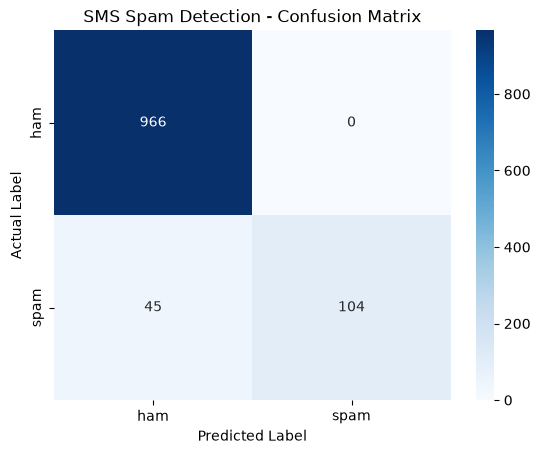

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt 
import seaborn as sns 

X = texts
y = data['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

tfidf_vectorizer = TfidfVectorizer()
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

model = MultinomialNB()
model.fit(X_train_tfidf, y_train)
y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test,y_pred)
# print(classification_report(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('SMS Spam Detection - Confusion Matrix')
plt.show()

In [10]:
results = pd.DataFrame({
    'message': X_test,
    'actual': y_test,
    'predicted': y_pred
})
false_negatives = results[
    (results['actual'] == 'spam') &
    (results['predicted'] == 'ham')
]

fn_messages = X_test.loc[false_negatives.index[:10]]
fn_vector = tfidf_vectorizer.transform(fn_messages)
spam_probabilities = model.predict_proba(fn_vector)[:, 1]
fn_analysis = pd.DataFrame({
    'message': fn_messages,
    'spam_probability': spam_probabilities
})

fn_analysis

,message,spam_probability
3059,unsubscribed services get tons sexy babes hunk...,0.139111
5,freemsg hey darling 3 weeks no word back id li...,0.065088
1022,guess somebody know secretly fancies wan na fi...,0.223165
3750,dear voucher holder 2 claim 1st class airport ...,0.308173
856,talk sexy make new friends fall love worlds di...,0.119528
3141,sexy sexy cum text im wet warm ready porn u fu...,0.365522
1663,hi ur lookin 4 saucy daytime fun wiv busty mar...,0.115431
3981,ringtoneking 84484,0.134171
3360,sorry missed call lets talk time im 07090201529,0.003801
3548,rock yr chik get 100s filthy films xxx pics yr...,0.392048


In [11]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score
fn_messages = X_test.loc[false_negatives.index]
fn_vector = tfidf_vectorizer.transform(fn_messages)
fn_probabilities = model.predict_proba(fn_vector)[:, 1]

# print("Minimum:", fn_probabilities.min())
# print("Maximum:", fn_probabilities.max())
# print("Mean:", fn_probabilities.mean())
# print("Median:", np.median(fn_probabilities))

# (fn_probabilities >= 0.3).sum()

spam_probs = model.predict_proba(X_test_tfidf)[:, 1]
y_pred_03 = np.where(spam_probs >= 0.3, 'spam', 'ham')
# print(classification_report(y_test, y_pred_03))

cm_03 = confusion_matrix(y_test, y_pred_03)
f1 = f1_score(y_test, y_pred_03, pos_label='spam')
f1

0.8856088560885609

In [12]:
threshold = [0.1, 0.2, 0.3, 0.4, 0.5]
precision_scores = []
recall_scores = []
f1_scores = []

spam_probs_01 = model.predict_proba(X_test_tfidf)[:, 1]
for value in threshold:
    y_pred_threshold = np.where(spam_probs_01 >= value, 'spam', 'ham')
    prec = precision_score(y_test, y_pred_threshold, pos_label='spam')
    precision_scores.append(prec)
    rec = recall_score(y_test, y_pred_threshold, pos_label='spam')
    recall_scores.append(rec)
    f1_01 = f1_score(y_test, y_pred_threshold, pos_label='spam')
    f1_scores.append(f1_01)

threshold_result = pd.DataFrame({
    "threshold": threshold,
    "precision": precision_scores,
    "recall": recall_scores,
    "f1": f1_scores
})

spam_probs_02 = model.predict_proba(X_test_tfidf)[:, 1]
y_pred_02 = np.where(spam_probs >= 0.2, 'spam', 'ham')

cm_02 = confusion_matrix(y_test, y_pred_02)
cm_02

array([[963,   3],
       [ 24, 125]])

In [14]:
import string
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import joblib

stop_words = stopwords.words('english')
stop_words.remove('not')
stop_words.remove('no')

def remove_stopwords(message):
    tokens = word_tokenize(message)
    filtered_tokens = [word for word in tokens if word not in stop_words]
    return filtered_tokens

new_messages = [
    "Hey, are you coming to class tomorrow?",
    "Congratulations! You have won a free gift voucher. Claim now!"
]
translator = str.maketrans('', '', string.punctuation)
new_cleaned = [
    message.lower().translate(translator)
    for message in new_messages
]
new_filtered = [remove_stopwords(message) for message in new_cleaned]
new_texts = [' '.join(words) for words in new_filtered]

X_new = tfidf_vectorizer.transform(new_texts)
X_new_prob = model.predict_proba(X_new)[:, 1]
X_pred_01 = np.where(X_new_prob >= 0.2, 'spam', 'ham')


joblib.dump(model, 'spam_classifier.pkl')
joblib.dump(tfidf_vectorizer, 'tfidf_vectorizer.pkl')

loaded_model = joblib.load('spam_classifier.pkl')
loaded_vectorizer = joblib.load('tfidf_vectorizer.pkl')

new = loaded_vectorizer.transform(new_texts)
new_pred = loaded_model.predict_proba(new)[:, 1]
new_pred


array([0.00207941, 0.8816812 ])

<class 'sklearn.naive_bayes.MultinomialNB'>
<class 'sklearn.feature_extraction.text.TfidfVectorizer'>
